<a href="https://colab.research.google.com/github/charlottemarieolexy-tech/A05-pca/blob/main/A05.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams.

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [1]:
import pickle

with open('all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)

from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens.
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.**

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions?

**Q3.**

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Charlotte Olexy

**Date:** 10/21/2026

In [2]:
# Your Phase 1 solution to the problem goes here.
# token_freq

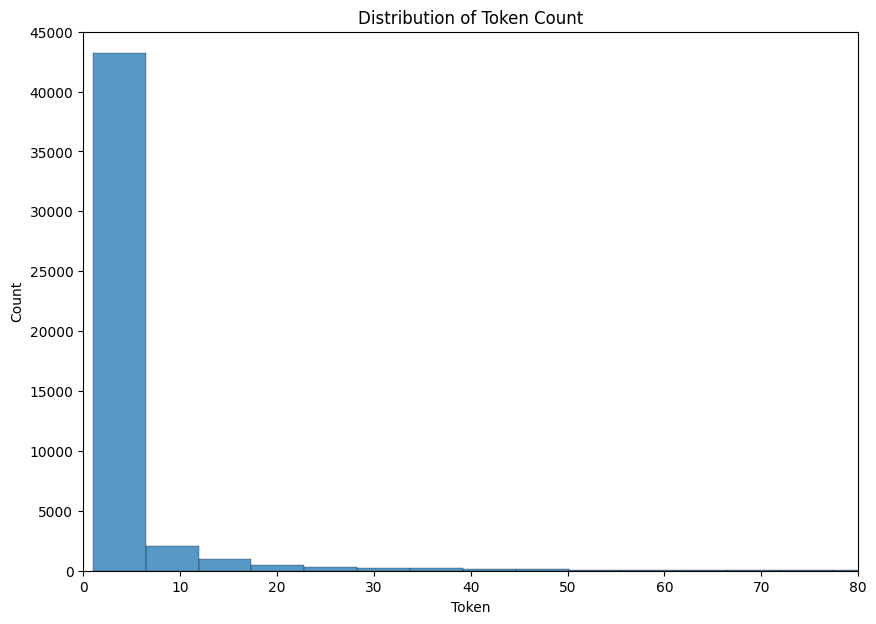

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

tokens = pd.DataFrame(token_freq, columns= ["Token", "Count"])

fig, ax  = plt.subplots(figsize=(10,7))

sns.histplot(
    data=tokens,
    x="Count",
    bins=250,
    ax=ax
)
ax.set_title("Distribution of Token Count")
ax.set_xlabel("Token")
plt.xlim(0,80)
plt.ylim(0, 45000)
plt.show()

#What do you notice about the frequency of occurrence of different tokens? How does it look?

The distribution is extremely skewed to the right. Most of the tokens have a count of 1-3, meaning that the frequency of the occurence of most of the tokens was relatively low. However, there are a few tokens that have a high count ranging from 10 to 65 in relation to the majority.

In [4]:
#Question 2 - Reading in the Phishing clean parquet file

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

emails = pd.read_parquet("Phishing_clean.parquet")
X = emails.drop(columns=["Email Type"])
y = emails["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, train_size=0.80, random_state=42)

regression = LinearRegression().fit(X_train, y_train)
print("R-squared (Train):",r2_score(y_train, regression.predict(X_train)))
print("R-squared (Test):",r2_score(y_test, regression.predict(X_test)), "\n")

coefs = pd.Series(regression.coef_, index=X.columns)

print(coefs.abs().sort_values(ascending=False).head(5))


R-squared (Train): 0.7670143724934355
R-squared (Test): 0.6658718438847919 

intervention         1.259257
localized            0.824350
thermal              0.747006
crawler              0.696167
background-image:    0.622909
dtype: float64


#What is the  R2  on the test set? On the training set? What words have the largest coefficients in absolute value and most strongly influence predictions?

The R squared differs between the training and test sets, with the training set having a greater R squared of 0.77 (stronger relationship) in comparison to the test set with an R squared of 0.67. The words with the top coefficients appear to be" intervention, localized, thermal, crawler, and background-image.

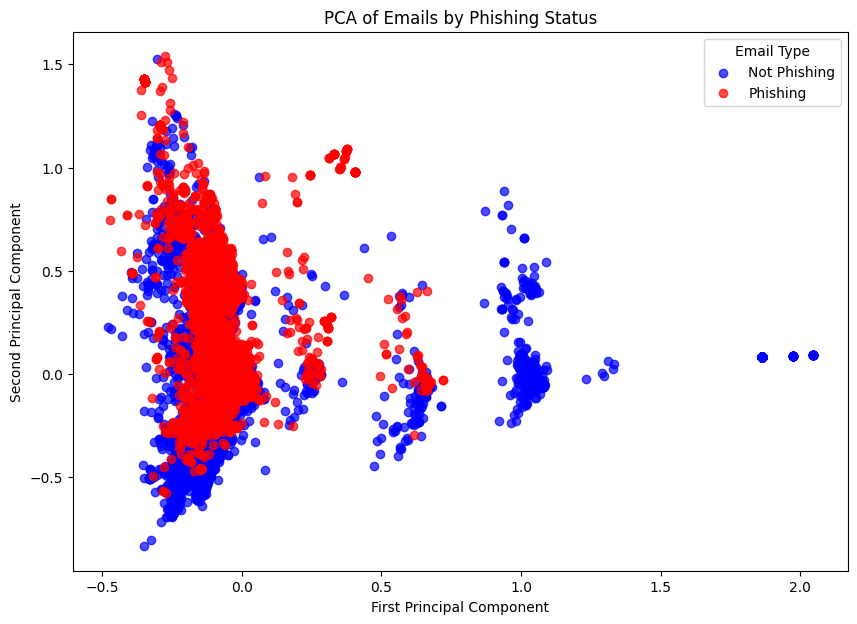

In [5]:
#Q3 - PCA
from sklearn.decomposition import PCA
import numpy as np

emails_pca = PCA(n_components=2).fit(X).transform(X)

fig, ax = plt.subplots(figsize=(10,7))

ax.scatter(
    x=emails_pca[y == 0, 0],
    y=emails_pca[y == 0, 1],
    color = 'blue',
    label = 'Not Phishing',
    alpha = 0.7,
)

ax.scatter(
    x=emails_pca[y == 1, 0],
    y=emails_pca[y == 1, 1],
    color ='red',
    label="Phishing",
    alpha=0.7
)

ax.set_xlabel("First Principal Component")
ax.set_ylabel("Second Principal Component")
ax.set_title("PCA of Emails by Phishing Status")
ax.legend(title='Email Type')

# Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

The PCA plots most of the phishing emails and non-phishing emails over top of each other near the y axis instead of two separate, distinct clusters. While the predictions of Not-Phishing Emails are more spread out, the large overlapping cluster of both Phishing and Non-Phishing emails indicates that the PC analysis with only 2 components does not do a good job of capturing enough of the variance in the data to more accurately predict which emails are scams vs. not.

In [6]:
#Q4 - 2610 Components
pca = PCA(n_components=2610)
emails_pca_2610_train = pca.fit_transform(X_train)
emails_pca_2610_test = pca.transform(X_test)

pca_reg = LinearRegression().fit(emails_pca_2610_train, y_train)

print("Principle Component Regression Train R2:", r2_score(y_train, pca_reg.predict(emails_pca_2610_train)))
print("Principle Component Regression Test R2:", r2_score(y_test, pca_reg.predict(emails_pca_2610_test)))
print("Variance explained by 2610 principle components:", pca.explained_variance_ratio_.sum())


Principle Component Regression Train R2: 0.7662326827745849
Principle Component Regression Test R2: 0.6683390643101164
Variance explained by 2610 principle components: 0.9998620409568273


#How does this performance compare to the linear regression?

The R2 for the PCA training set regression is 0.766 and the test set regression is 0.668. This is very similar to the R2 from the linear regression which was 0.767 for the training set and 0.666. The R2s being very similar in value makes sense because the PCA captures 99.986% of the variance which essentially is almost all of the components that affect the variation in R2 in the linear regression. Since we only dropped 101 of the components with the lowest-variance(from 2,711 to 2610), not much from the data was removed, changing the fit very minimally. Despite this trivial difference, there is still a slight change. Since the R2 of the training set is lowered from 0.767 to 0.766 by dropping some direction and the R2 of the test set is raised from 0.666 to 0.668, dropping a few noisy, low variance components indicates that the PCA did slightly improve the fit.

# Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

The original data is noisy, with thousands of word columns that sometimes overlap, presenting issues of multicollinearity and instability. When we run a regression on the original data, this noisy data makes the model more unstable and prone to overfitting. Principal components, 2610 in this case, help combine these overlapping/highly correlated words to produce a new set of variables that are uncorrelated with one another and ordered by the information they provide about the data's variance so we can drop the lower variance components that may reduce model complexity.
In our case, we only dropped 101 out of 2711 components which is only 3.7% of all the components and why it didn't change the R2 by much. If we were to drop a few more components (but not too many more), the PCA should allow for a more stable, better performing model.  



## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [7]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]